# 04 · Route Validation & Folium Maps (Member 4)

**Goal.** Check the ground-truth `.route` files of every available trip, measure how far the GPS points lie from the route,
and draw interactive Folium maps for a few trips.

| Check | Question |
|---|---|
| Route ID validity | Is every arc ID in `.route` a valid row index of the trip's `.arcs`? |
| Continuity | Does each arc end where the next arc starts (`to_node(aᵢ) == from_node(aᵢ₊₁)`)? |
| GPS-to-route distance | How far (metres) is each `.track` point from the nearest route segment? |
| Maps | Route, GPS points, start / end and route breaks for 4 trips |

**Scope / data rules.** Only the `train` (80) and `student-test` (10) partitions are used. Evaluator routes are never read
(`load_route_trip` refuses evaluator partitions).

**Reused code.** Member 1's loader (raw readers, UTM projection) and Member 3's `pathsnap.road_network`
(nodes / arcs, `MultiDiGraph` with edge key = `arc_id`, segment geometry). All new logic is in
[`src/pathsnap/route_validation.py`](../src/pathsnap/route_validation.py).

## 1. Setup

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from pathsnap.data.loader import discover_trips          # Member 1
from pathsnap.utils.config import get_raw_data_dir
from pathsnap import road_network as rn                   # Member 3
from pathsnap import route_validation as rv               # Member 4

SEED = 42
OUT_DIR = REPO_ROOT / "outputs" / "route_validation"
FIG_DIR = OUT_DIR / "figures"
MAP_DIR = REPO_ROOT / "outputs" / "maps"
for d in (FIG_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

trips_index = discover_trips(get_raw_data_dir())
split = rn.load_split()
plan = [(t, p) for p in ("train", "student-test") for t in split[p] if t in trips_index]
print(f"Trips to analyse: {len(plan)} "
      f"(train {sum(p == 'train' for _, p in plan)}, student-test {sum(p == 'student-test' for _, p in plan)})")

[INFO] 2026-11-18 11:58:11,670 - pathsnap.data.loader: Discovered 90 trips in C:\Users\Mateen\OneDrive\Desktop\ML-Hackathon-PT-082\data\raw


Trips to analyse: 90 (train 80, student-test 10)


## 2. Run all checks
`rv.analyse_route_trip()` loads one trip, validates route IDs, checks continuity, computes GPS-to-route distances and
returns small results. The road graph is only built for trips whose route has a break (to search for a connecting path),
and it is released immediately.

In [2]:
summaries, dist_summaries, breaks, distances = [], [], [], []
t0 = time.time()
for tid, part in plan:
    res = rv.analyse_route_trip(tid, part, trips_index)
    summaries.append(res["summary"])
    if not res["ok"]:
        print("Could not analyse", tid, res["summary"]["load_errors"]); continue
    dist_summaries.append(res["distance_summary"])
    breaks.append(res["breaks"])
    if res["distances"] is not None:
        distances.append(res["distances"])
print(f"Analysed {len(summaries)} trips in {time.time() - t0:.1f} s")

route_summary = pd.DataFrame(summaries)
gps_summary = pd.DataFrame(dist_summaries)
route_breaks = pd.concat(breaks, ignore_index=True)
all_dist = pd.concat(distances, ignore_index=True).merge(route_summary[["trip_id", "partition"]], on="trip_id")

Analysed 90 trips in 21.7 s


## 3. Route ID validity
* `invalid_arc_ids` – route entries outside `0 … n_arcs-1`;
* `consecutive_repeats` – the same arc twice in a row;
* `revisited_arcs` – arcs that appear again later in the route (e.g. the vehicle drove the same street twice).

In [3]:
id_cols = ["trip_id", "partition", "n_arcs_in_network", "route_length", "invalid_arc_ids", "unique_arcs",
           "consecutive_repeats", "revisited_arcs", "route_length_km", "load_errors"]
with pd.option_context("display.max_rows", 100):
    display(route_summary[id_cols])
print("Total route entries      :", int(route_summary.route_length.sum()))
print("Invalid route arc IDs    :", int(route_summary.invalid_arc_ids.sum()))
print("Consecutive repeats      :", int(route_summary.consecutive_repeats.sum()))
print("Trips with revisited arcs:", int((route_summary.revisited_arcs > 0).sum()),
      "| max revisited arcs in one trip:", int(route_summary.revisited_arcs.max()),
      f"(trip {route_summary.loc[route_summary.revisited_arcs.idxmax(), 'trip_id']})")
print("Load errors              :", int((route_summary.load_errors.fillna('') != '').sum()))
display(route_summary.groupby("partition")[["route_length", "route_length_km"]].describe().T.round(1))

,trip_id,partition,n_arcs_in_network,route_length,invalid_arc_ids,unique_arcs,consecutive_repeats,revisited_arcs,route_length_km,load_errors
0,00000001,train,165790,525,0,525,0,0,49.855,
1,00000002,train,16139,262,0,262,0,0,7.963,
2,00000003,train,18028,79,0,79,0,0,5.005,
3,00000004,train,15499,320,0,320,0,0,25.547,
4,00000005,train,1579,105,0,105,0,0,30.862,
5,00000006,train,6757,261,0,261,0,0,16.143,
6,00000008,train,10421,173,0,172,0,1,9.349,
7,00000010,train,15715,210,0,210,0,0,11.404,
8,00000011,train,5393,565,0,565,0,0,51.768,
9,00000012,train,38599,205,0,205,0,0,40.049,


Total route entries      : 34813
Invalid route arc IDs    : 0
Consecutive repeats      : 0
Trips with revisited arcs: 10 | max revisited arcs in one trip: 217 (trip 00000056)
Load errors              : 0


partition              student-test   train
route_length    count          10.0    80.0
                mean          347.7   391.7
                std           359.6   361.2
                min            95.0    59.0
                25%           153.5   168.2
                50%           250.0   280.0
                75%           357.8   480.5
                max          1323.0  2266.0
route_length_km count          10.0    80.0
                mean           24.8    27.8
                std            21.2    25.7
                min             5.3     5.0
                25%             9.9     8.9
                50%            14.7    14.3
                75%            40.2    39.4
                max            64.8    94.1

## 4. Route continuity
Each consecutive pair of route arcs is classified as

| status | meaning |
|---|---|
| `connected` | `to_node(aᵢ) == from_node(aᵢ₊₁)` (expected) |
| `same_arc` | the same arc repeated |
| `shares_node` | arcs touch, but not head-to-tail (direction mismatch) |
| `gap` | arcs do not touch |

For every non-connected transition we report the straight-line gap and whether a **directed** path exists in the road
graph between the end of `aᵢ` and the start of `aᵢ₊₁` (shortest path by length, Member 3's graph).

In [4]:
print("Transitions checked:", int(route_summary.transitions.sum()))
display(route_summary[["connected", "same_arc", "shares_node", "gaps"]].sum().rename("transitions").to_frame())
print("Continuous routes:", int(route_summary.is_continuous.sum()), "of", len(route_summary))
print("Trips with at least one break:", route_breaks.trip_id.nunique())
display(route_breaks.round(1))

Transitions checked: 34723


,transitions
connected,34709
same_arc,0
shares_node,1
gaps,13


Continuous routes: 79 of 90
Trips with at least one break: 11


,trip_id,position,arc_id,next_arc_id,end_node,next_start_node,status,gap_m,path_exists,path_arcs,path_m
0,00000002,53,1848,10863,5059,5289,gap,324.7,True,41,1055.9
1,00000019,94,85589,51027,849,23488,gap,241.0,True,17,363.5
2,00000019,151,55059,55050,25413,25408,gap,255.2,True,12,511.8
3,00000019,300,953,23709,10107,10862,gap,595.8,True,6,598.5
4,00000033,164,1003,1002,1283,563,shares_node,91.9,True,1,91.9
5,00000041,12,1264,519,349,348,gap,57.2,True,6,402.8
6,00000042,1212,14661,17989,1762,8726,gap,30.7,True,1,30.7
7,00000069,153,10165,10172,5083,5084,gap,40.9,True,6,62.3
8,00000075,31,507,509,250,227,gap,10.6,True,18,923.2
9,00000075,62,134,552,229,247,gap,73.0,True,27,1208.9


In [5]:
if len(route_breaks):
    rb = route_breaks.copy()
    rb["detour_ratio"] = pd.to_numeric(rb.path_m, errors="coerce") / rb.gap_m
    print("Breaks with a directed connecting path:", int((rb.path_exists == True).sum()), "of", len(rb))
    print("Breaks with NO directed path          :", rb.loc[rb.path_exists == False, ["trip_id", "position", "arc_id", "next_arc_id"]].to_dict("records"))
    print("Gap distance (m): median %.1f, max %.1f" % (rb.gap_m.median(), rb.gap_m.max()))
    print("Arcs missing along the shortest connecting path: median %.0f, max %.0f" % (pd.to_numeric(rb.path_arcs, errors="coerce").median(), pd.to_numeric(rb.path_arcs, errors="coerce").max()))

Breaks with a directed connecting path: 13 of 14
Breaks with NO directed path          : [{'trip_id': '00000086', 'position': 1, 'arc_id': 230068, 'next_arc_id': 96025}]
Gap distance (m): median 82.5, max 595.8
Arcs missing along the shortest connecting path: median 7, max 41


## 5. GPS-to-route distance
Every GPS point is projected to the trip's UTM zone (Member 1's `compute_utm_epsg` / `project_coordinates`) and its
perpendicular distance to the nearest route segment is computed. Small distances (a few metres) are GPS noise; large
ones mean the GPS and the labelled route disagree (GPS outside the route's time span, a parallel road, or bad points).

In [6]:
with pd.option_context("display.max_rows", 100):
    display(gps_summary)
x = all_dist.distance_m
print(f"All {len(x):,} GPS points: median {x.median():.2f} m, mean {x.mean():.2f} m, p90 {x.quantile(.9):.2f} m, "
      f"p95 {x.quantile(.95):.2f} m, max {x.max():.1f} m")
for k in (10, 20, 50, 100):
    print(f"  share of points > {k:>3} m: {100 * (x > k).mean():.2f} %")

,trip_id,partition,gps_points,mean_m,median_m,p90_m,p95_m,max_m,pct_over_20m,pct_over_50m,pct_over_100m
0,00000001,train,1315,5.02,4.29,10.20,12.41,27.22,0.228,0.000,0.000
1,00000002,train,7243,33.79,5.67,97.79,242.36,569.66,15.353,11.984,9.927
2,00000003,train,821,5.45,4.44,11.82,13.99,25.79,0.609,0.000,0.000
3,00000004,train,1064,11.63,8.52,25.80,29.50,44.62,23.966,0.000,0.000
4,00000005,train,1045,5.39,4.53,11.02,13.24,27.05,1.435,0.000,0.000
5,00000006,train,1450,5.38,4.48,11.45,13.73,25.42,0.276,0.000,0.000
6,00000008,train,3093,9.89,7.46,21.11,27.28,71.35,11.348,0.679,0.000
7,00000010,train,2711,6.18,4.81,12.98,16.86,37.80,2.840,0.000,0.000
8,00000011,train,2828,6.03,5.12,12.37,14.55,32.15,1.025,0.000,0.000
9,00000012,train,1608,6.17,5.11,12.80,15.79,30.54,1.990,0.000,0.000


All 227,577 GPS points: median 5.57 m, mean 20.18 m, p90 48.69 m, p95 137.70 m, max 569.7 m
  share of points >  10 m: 26.82 %
  share of points >  20 m: 13.16 %
  share of points >  50 m: 9.93 %
  share of points > 100 m: 8.79 %


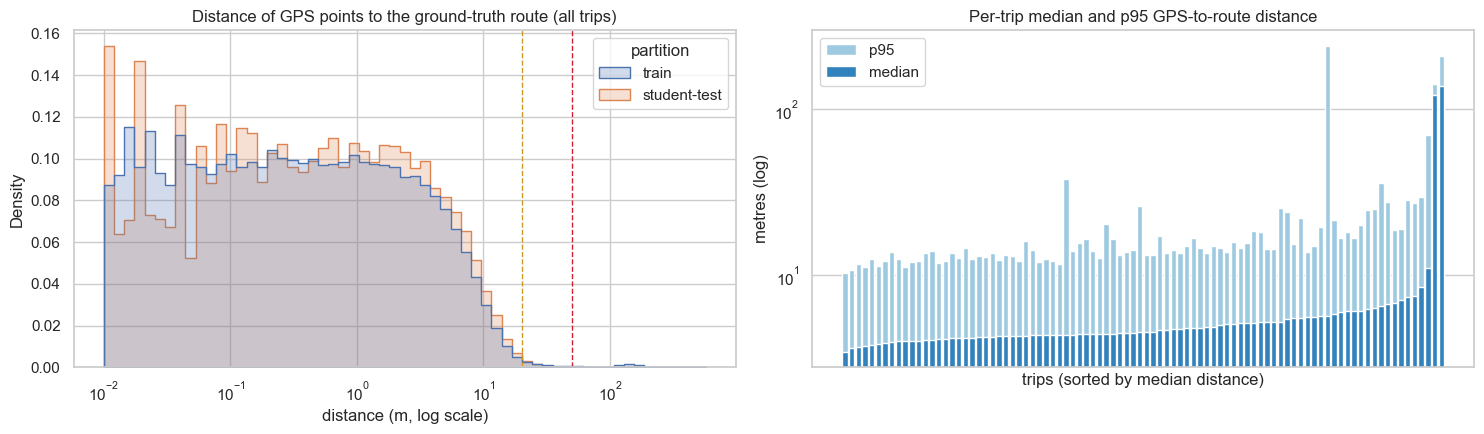

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.logspace(np.log10(max(x.min(), 0.01)), np.log10(x.max()), 60)
sns.histplot(data=all_dist, x="distance_m", hue="partition", bins=bins, ax=axes[0], element="step", stat="density", common_norm=False)
axes[0].set(xscale="log", title="Distance of GPS points to the ground-truth route (all trips)", xlabel="distance (m, log scale)")
for k, c in ((20, "#d29922"), (50, "#cf222e")):
    axes[0].axvline(k, color=c, ls="--", lw=1)
order = gps_summary.sort_values("median_m")
axes[1].bar(np.arange(len(order)), order.p95_m, color="#9ecae1", label="p95")
axes[1].bar(np.arange(len(order)), order.median_m, color="#3182bd", label="median")
axes[1].set(yscale="log", xticks=[], xlabel="trips (sorted by median distance)", ylabel="metres (log)",
            title="Per-trip median and p95 GPS-to-route distance")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "gps_route_distance.png", dpi=120); plt.show()

### 5.1 Trips where GPS and route disagree
Trips whose **median** distance exceeds 20 m, or whose p95 exceeds 50 m, are inspected over time. Splitting each track
into 10 equal parts shows whether the disagreement affects the whole trip (constant offset / different road) or only a
part (e.g. GPS recorded after the route ends).

,trip_id,partition,gps_points,median_m,p95_m,max_m,pct_over_50m
1,00000002,train,7243,5.67,242.36,569.66,11.984
44,00000054,train,19313,138.59,210.05,241.26,87.242
26,00000033,train,5844,122.41,142.06,160.46,58.949
35,00000043,train,2322,10.99,70.22,193.57,7.192


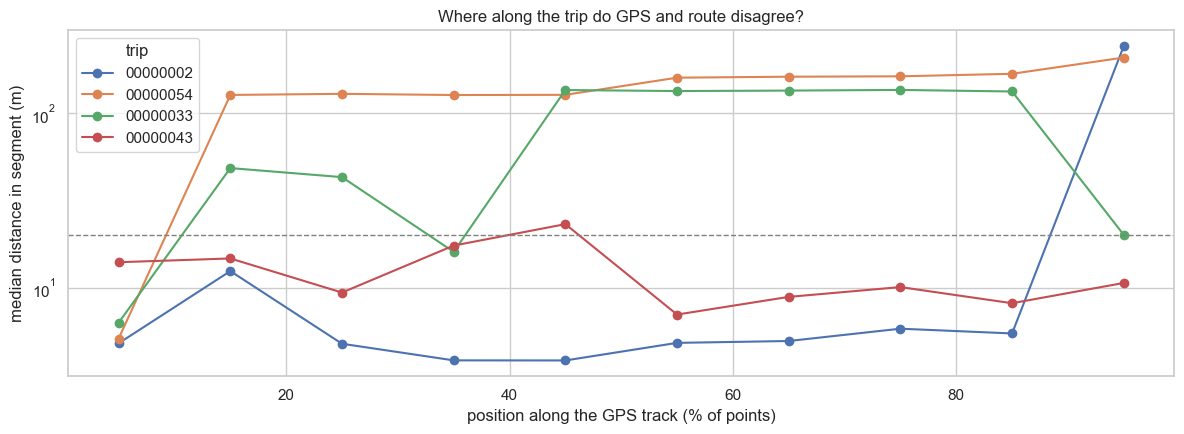

,0-10%,10-20%,20-30%,30-40%,40-50%,50-60%,60-70%,70-80%,80-90%,90-100%
00000002,4.8,12.5,4.8,3.8,3.8,4.8,4.9,5.8,5.5,242.5
00000054,5.1,127.3,129.2,127.2,127.5,159.9,162.0,162.8,168.3,208.5
00000033,6.3,48.5,43.0,16.1,135.8,134.0,134.9,136.0,133.3,20.1
00000043,14.0,14.7,9.4,17.4,23.1,7.0,8.9,10.1,8.2,10.6


In [8]:
odd = gps_summary[(gps_summary.median_m > 20) | (gps_summary.p95_m > 50)].sort_values("p95_m", ascending=False)
display(odd[["trip_id", "partition", "gps_points", "median_m", "p95_m", "max_m", "pct_over_50m"]])
fig, ax = plt.subplots(figsize=(12, 4.5))
profile = {}
for tid in odd.trip_id:
    d = all_dist[all_dist.trip_id == tid].distance_m.to_numpy()
    profile[tid] = [np.median(c) for c in np.array_split(d, 10)]
    ax.plot(np.arange(5, 100, 10), profile[tid], marker="o", label=tid)
ax.set(yscale="log", xlabel="position along the GPS track (% of points)", ylabel="median distance in segment (m)",
       title="Where along the trip do GPS and route disagree?")
ax.axhline(20, color="0.5", ls="--", lw=1); ax.legend(title="trip")
plt.tight_layout(); plt.savefig(FIG_DIR / "disagreement_profile.png", dpi=120); plt.show()
display(pd.DataFrame(profile, index=[f"{i*10}-{i*10+10}%" for i in range(10)]).T.round(1))

## 6. Folium maps
Four trips are mapped, chosen deterministically:

1. the **median-length** train route (a typical trip);
2. the train trip with the **most route breaks**;
3. the trip with the **largest median GPS-to-route distance**;
4. the **median-length** student-test route.

Each map shows the route (blue; drawn as separate pieces where it breaks), GPS points coloured by distance to the route
(green ≤ 20 m, amber 20–50 m, red > 50 m; at most 1,500 points, sampled with seed 42), GPS start / end, and red markers at
route breaks. Layers can be toggled. Maps are saved to `outputs/maps/route_<trip_id>.html`.

In [9]:
def median_trip(df):
    return df.iloc[(df.route_length - df.route_length.median()).abs().argsort().iloc[0]].trip_id

train_rs = route_summary[route_summary.partition == "train"]
br = train_rs.assign(n_breaks=train_rs.shares_node + train_rs.gaps)
choices = {
    "typical train trip (median route length)": median_trip(train_rs),
    "most route breaks": br.sort_values(["n_breaks", "trip_id"], ascending=[False, True]).trip_id.iloc[0],
    "largest median GPS-to-route distance": gps_summary.sort_values("median_m", ascending=False).trip_id.iloc[0],
    "typical student-test trip": median_trip(route_summary[route_summary.partition == "student-test"]),
}
part_of = dict(zip(route_summary.trip_id, route_summary.partition))
maps = {}
for why, tid in choices.items():
    d = rv.load_route_trip(tid, trips_index, part_of[tid])
    cont = rv.check_route_continuity(d["route"], d["arcs"], d["nodes"])
    dist = all_dist[all_dist.trip_id == tid].reset_index(drop=True)
    m = rv.make_route_map(tid, d["track"], d["nodes"], d["arcs"], d["route"], continuity=cont, distances=dist, seed=SEED)
    path = MAP_DIR / f"route_{tid}.html"
    m.save(str(path))
    maps[tid] = m
    print(f"{why:45s} -> trip {tid}: {len(d['route'])} arcs, {len(d['track'])} GPS points, "
          f"{int((~cont.status.isin(['connected', 'same_arc'])).sum())} breaks -> {path.relative_to(REPO_ROOT).as_posix()}")

typical train trip (median route length)      -> trip 00000025: 283 arcs, 1179 GPS points, 0 breaks -> outputs/maps/route_00000025.html


most route breaks                             -> trip 00000019: 545 arcs, 2354 GPS points, 3 breaks -> outputs/maps/route_00000019.html


largest median GPS-to-route distance          -> trip 00000054: 422 arcs, 19313 GPS points, 0 breaks -> outputs/maps/route_00000054.html


typical student-test trip                     -> trip 00000091: 232 arcs, 874 GPS points, 0 breaks -> outputs/maps/route_00000091.html


The typical student-test trip, rendered inline (the other maps are in `outputs/maps/`):

In [10]:
maps[choices["typical student-test trip"]]

## 7. Verification on real trips
Sanity checks of the reusable functions on one train trip and one student-test trip:
route IDs map to real arcs, continuity statuses agree with a direct node comparison, and GPS distances are
non-negative, finite and one per track point.

In [11]:
for part in ("train", "student-test"):
    tid = split[part][0]
    d = rv.load_route_trip(tid, trips_index, part)
    ids = rv.validate_route_ids(d["route"], len(d["arcs"]))
    assert ids["invalid_arc_ids"] == 0 and ids["route_length"] == len(d["route"])
    cont = rv.check_route_continuity(d["route"], d["arcs"], d["nodes"])
    a = d["arcs"].set_index("arc_id")
    direct = a.loc[d["route"][:-1], "to_node_id"].to_numpy() == a.loc[d["route"][1:], "from_node_id"].to_numpy()
    assert ((cont.status == "connected").to_numpy() == direct).all()
    dist = rv.gps_to_route_distances(d["track"], d["nodes"], d["arcs"], d["route"])
    assert len(dist) == len(d["track"]) and np.isfinite(dist.distance_m).all() and (dist.distance_m >= 0).all()
    assert dist.nearest_arc_id.isin(d["route"]).all()
    print(f"{part:12s} trip {tid}: route {ids['route_length']} arcs, {int(direct.sum())}/{len(direct)} connected, "
          f"median GPS distance {dist.distance_m.median():.2f} m  ✓")
try:
    rv.load_route_trip(split["train"][0], trips_index, "evaluator-testing")
    raise AssertionError("evaluator guard failed")
except PermissionError:
    print("Evaluator guard: route loading refused for evaluator partition  ✓")

train        trip 00000001: route 525 arcs, 524/524 connected, median GPS distance 4.29 m  ✓
student-test trip 00000000: route 179 arcs, 178/178 connected, median GPS distance 6.03 m  ✓
Evaluator guard: route loading refused for evaluator partition  ✓


## 8. Export

In [12]:
route_summary.to_csv(OUT_DIR / "route_summary.csv", index=False)
route_breaks.to_csv(OUT_DIR / "route_breaks.csv", index=False)
gps_summary.to_csv(OUT_DIR / "gps_route_distance_summary.csv", index=False)
for f in sorted([*OUT_DIR.rglob("*.*"), *MAP_DIR.glob("route_*.html")]):
    print(f"{f.relative_to(REPO_ROOT).as_posix():55s} {f.stat().st_size / 1024:8.1f} KB")

outputs/maps/route_00000019.html                          1094.2 KB
outputs/maps/route_00000025.html                           858.3 KB
outputs/maps/route_00000054.html                          1092.0 KB
outputs/maps/route_00000091.html                           634.8 KB
outputs/route_validation/figures/disagreement_profile.png     88.5 KB
outputs/route_validation/figures/gps_route_distance.png     56.7 KB
outputs/route_validation/gps_route_distance_summary.csv      5.7 KB
outputs/route_validation/route_breaks.csv                    1.2 KB
outputs/route_validation/route_summary.csv                   5.8 KB


## 9. Findings

In [13]:
rs, gs = route_summary, gps_summary
n_br = len(route_breaks)
facts = [
    f"{len(rs)} trips checked ({(rs.partition == 'train').sum()} train, {(rs.partition == 'student-test').sum()} student-test); "
    f"{int(rs.route_length.sum()):,} route entries, route length {int(rs.route_length.min())}–{int(rs.route_length.max())} arcs "
    f"({rs.route_length_km.min():.1f}–{rs.route_length_km.max():.1f} km).",
    f"Invalid route arc IDs: {int(rs.invalid_arc_ids.sum())}. Consecutive repeated arcs: {int(rs.consecutive_repeats.sum())}. "
    f"Trips that revisit an arc: {int((rs.revisited_arcs > 0).sum())}.",
    f"{int(rs.connected.sum()):,} of {int(rs.transitions.sum()):,} transitions connect head-to-tail; "
    f"{int(rs.is_continuous.sum())} of {len(rs)} routes are fully continuous.",
    f"{n_br} breaks in {route_breaks.trip_id.nunique()} trips ({int(rs.gaps.sum())} gaps, {int(rs.shares_node.sum())} direction mismatch); "
    f"{int((route_breaks.path_exists == True).sum())} can be bridged by a directed path in the road graph, "
    f"{int((route_breaks.path_exists == False).sum())} cannot.",
    f"GPS-to-route distance over {len(all_dist):,} points: median {all_dist.distance_m.median():.2f} m, "
    f"p95 {all_dist.distance_m.quantile(.95):.2f} m; per-trip median ranges {gs.median_m.min():.2f}–{gs.median_m.max():.2f} m.",
    f"{int((gs.median_m <= 10).sum())} trips have a median distance ≤ 10 m; "
    f"{int((gs.median_m > 20).sum())} trips have a median > 20 m: {', '.join(gs.loc[gs.median_m > 20, 'trip_id'])}.",
]
for i, f in enumerate(facts, 1):
    print(f"{i}. {f}")

1. 90 trips checked (80 train, 10 student-test); 34,813 route entries, route length 59–2266 arcs (5.0–94.1 km).
2. Invalid route arc IDs: 0. Consecutive repeated arcs: 0. Trips that revisit an arc: 10.
3. 34,709 of 34,723 transitions connect head-to-tail; 79 of 90 routes are fully continuous.
4. 14 breaks in 11 trips (13 gaps, 1 direction mismatch); 13 can be bridged by a directed path in the road graph, 1 cannot.
5. GPS-to-route distance over 227,577 points: median 5.57 m, p95 137.70 m; per-trip median ranges 3.45–138.59 m.
6. 87 trips have a median distance ≤ 10 m; 2 trips have a median > 20 m: 00000033, 00000054.


### Interpretation and implications
* **Route labels are structurally valid.** Every route arc ID points to a real arc and almost every transition connects
  head-to-tail, so `.route` can be used directly as ground truth for training and evaluation.
* **Breaks are rare and mostly bridgeable.** Most breaks can be closed by a directed path through the road graph, which
  suggests skipped arcs in the label rather than impossible movements. Evaluation code should not assume every route is
  a single connected path; accuracy metrics should be computed on arc sets / lengths, not on path continuity.
  The break listed above without any directed path should be excluded or handled specially in transition-probability
  estimation.
* **GPS noise is small for typical trips.** For most trips the median distance is a few metres, which supports an HMM
  emission model with σ on the order of a few metres to ~10 m (to be fitted on training trips only).
* **A few trips disagree strongly.** For the trips in Section 5.1 the distance profile shows where the GPS leaves the
  route: in some only at the start or end (GPS recorded outside the route's time span), in others for most of the trip
  (GPS following a road roughly 100+ m away from the labelled arcs). These trips should be checked on the maps and
  considered for down-weighting or exclusion when fitting emission parameters.